<div style="border-left:4px solid #3D6FB0;padding:6px 0 8px 16px;"><div style="opacity:.72;font-size:12px;letter-spacing:1.4px;">Minería de Datos · Proyecto Final</div><div style="color:#3D6FB0;font-size:27px;font-weight:700;margin-top:4px;">Ajuste del umbral de decisión</div><div style="opacity:.72;font-size:14px;margin-top:6px;margin-bottom:10px;">Miguel A. Garcia, Nadia Ramos, Ángel J. Zamora</div><img src="https://mmss.iimas.unam.mx/dmmss/wp-content/uploads/2026/02/cropped-LogoUNAM_IIMAS_Negro50-scaled-2.png" width="200"/></div>

**Dónde estamos.** El sistema principal (LR sobre texto, `evaluacion.ipynb`) obtuvo 0.676 de F1 de fake en el test, con precisión de 0.839 y exhaustividad de 0.566: es conservador, deja pasar el 43 % de las falsas. Un clasificador de regresión logística no da solo una clase, da una **probabilidad** de que la noticia sea falsa, y la clase sale de comparar esa probabilidad con un **umbral** (por defecto 0.5).

**Para dónde vamos.** Si bajamos el umbral, el modelo marca más noticias como falsas: sube la exhaustividad y baja la precisión. La F1 de fake equilibra las dos, así que existe un umbral que la maximiza. Lo elegimos **solo con CV agrupada** (`notas/siguientes_pasos.md`, paso 1), medimos su efecto con una CV anidada y lo aplicamos **una sola vez** en el test. Como el test ya se vio en `evaluacion.ipynb`, el resultado se reporta como **sistema aparte**; el principal no cambia.

El modelo y su representación no cambian: solo cambia la regla que convierte la probabilidad en clase. Escribe `resultados/umbral_cv.csv`, `resultados/umbral_anidado.csv`, `resultados/umbral_test.csv`, `resultados/predicciones_test_umbral.csv`, `modelos/config_umbral.json` y dos figuras en `figuras/`.

## Contenido

    * [Sección 0: Configuración](#seccion-0)
* **[Metodología CRISP-DM: Modelado (umbral)](#fase-modelado)**
    * [Sección 1: Probabilidades fuera de fold](#seccion-1)
    * [Sección 2: F1 de fake según el umbral](#seccion-2)
    * [Sección 3: Estimación honesta con CV anidada](#seccion-3)
* **[Metodología CRISP-DM: Evaluación (sistema aparte)](#fase-evaluacion)**
    * [Sección 4: Aplicación única en el test](#seccion-4)
    * [Sección 5: Qué noticias cambian](#seccion-5)
* **[Conclusiones](#conclusiones)**
    * [Sección 6: Resumen y limitaciones](#seccion-6)

<a id="seccion-0"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 0: Configuración</span></div>

> **Qué se hace:** cargamos bibliotecas, constantes y datos preparados.
>
> **Qué se espera ver:** el entorno `fakedes` y las 961 noticias de `corpus.parquet`.

### 0.1 Bibliotecas

In [1]:
# Manejo de datos
import json
import os
import numpy as np
import pandas as pd

# Visualización
import matplotlib.pyplot as plt

# Evaluación
from scipy import stats
from sklearn.metrics import confusion_matrix

# Funciones compartidas del proyecto
import utils_fakedes as uf
from utils_fakedes import guardar, guardar_csv

### 0.2 Constantes

In [2]:
SEMILLA = uf.SEMILLA
TINTA, TINTA_SUAVE = uf.TINTA, uf.TINTA_SUAVE
UMBRALES = np.round(np.arange(0.20, 0.801, 0.01), 2)   # rejilla de umbrales que se prueban
UMBRAL_DEFECTO = 0.5
N_BOOTSTRAP = 1000                                      # los mismos remuestreos que evaluacion.ipynb
BASELINE_OFICIAL = 0.7217
uf.configurar_graficas()
uf.crear_carpetas(uf.RUTA_RESULTADOS, uf.RUTA_FIGURAS, 'modelos')

### 0.3 Datos y configuración del principal

In [3]:
corpus = pd.read_parquet(os.path.join(uf.RUTA_PROCESADOS, 'corpus.parquet'))
with open(os.path.join(uf.RUTA_RESULTADOS, 'seleccion_lineal.json'), encoding = 'utf-8') as f:
    config = json.load(f)['elegida']
y = corpus['Category'].values
folds = corpus['fold_grupo'].values
print(f'Noticias: {len(corpus)}; folds: {sorted(set(folds))}')
config

Noticias: 961; folds: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


{'representacion': 'palabras (1,2) + caracteres (2,5)',
 'estructura': 'solo texto',
 'sin_medio': True,
 'min_df': 20,
 'minusculas': True,
 'estilo': False,
 'k_chi2': None,
 'modelo': 'LR',
 'valor': 1.0}

<a id="fase-modelado"></a>

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Metodología CRISP-DM: Modelado (umbral)</span></div>

<a id="seccion-1"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 1: Probabilidades fuera de fold</span></div>

> **Qué se hace:** para cada fold entrenamos el principal con los otros 4 y guardamos la probabilidad de *fake* de cada noticia del fold que quedó fuera.
>
> **Qué se espera ver:** que con el umbral 0.5 se reproduzca la F1 de 0.730 de `modelos_lineales.ipynb` (si no, algo cambió en los datos o el código).

#### Glosario de la sección
* **Probabilidad fuera de fold:** probabilidad que da un modelo que **no** vio esa noticia al entrenar. Así, elegir el umbral con ellas no usa información de las respuestas que se están evaluando.
* **Umbral:** valor de corte. Si la probabilidad de *fake* es ≥ umbral, la noticia se predice como *Fake*.

In [4]:
def probabilidad_fake(entrenamiento, validacion):
    '''
    Función que entrena el principal con unas noticias y devuelve la probabilidad de fake de otras

    inputs:
    --------
        entrenamiento (pandas.DataFrame): Noticias para entrenar
        validacion (pandas.DataFrame): Noticias a predecir

    outputs:
    --------
        numpy.ndarray: Probabilidad de 'Fake' de cada noticia de validacion
    '''
    modelo = uf.construir_pipeline(config).fit(entrenamiento, entrenamiento['Category'])
    columna = list(modelo.classes_).index('Fake')
    return modelo.predict_proba(validacion)[:, columna]

def clases(prob, umbral):
    '''
    Función que convierte probabilidades de fake en clases con un umbral

    inputs:
    --------
        prob (numpy.ndarray): Probabilidades de 'Fake'
        umbral (float): Valor de corte

    outputs:
    --------
        numpy.ndarray: 'Fake' si prob >= umbral; 'True' en otro caso
    '''
    return np.where(prob >= umbral, 'Fake', 'True')

prob_oof = np.zeros(len(corpus))
for k in range(5):
    en_fold = folds == k
    prob_oof[en_fold] = probabilidad_fake(corpus[~en_fold], corpus[en_fold])

**Tabla 1.1.** Verificación: F1 de fake por fold con el umbral 0.5 contra la guardada en `reproducibilidad.xlsx` (hoja *resumen*).

In [5]:
guardada = [0.7848, 0.8541, 0.6345, 0.6375, 0.7381]
f1_05 = [uf.f1_fake(y[folds == k], clases(prob_oof[folds == k], UMBRAL_DEFECTO)) for k in range(5)]
verif = pd.DataFrame({'fold': range(5), 'F1 fake (umbral 0.5)': np.round(f1_05, 4), 'guardada': guardada})
verif['resultado'] = np.where(np.abs(verif['F1 fake (umbral 0.5)'] - verif['guardada']) < 0.0005, '✅', '❌')
print(f'Media: {np.mean(f1_05):.4f} (guardada 0.7298)')
verif

Media: 0.7298 (guardada 0.7298)


,fold,F1 fake (umbral 0.5),guardada,resultado
0,0,0.7848,0.7848,✅
1,1,0.8541,0.8541,✅
2,2,0.6345,0.6345,✅
3,3,0.6375,0.6375,✅
4,4,0.7381,0.7381,✅


**Tabla 1.2.** Cómo se reparten las probabilidades fuera de fold por clase real.

In [6]:
pd.DataFrame({'clase real': ['Fake', 'True'],
              'mediana': [np.median(prob_oof[y == 'Fake']), np.median(prob_oof[y == 'True'])],
              'percentil 10': [np.percentile(prob_oof[y == 'Fake'], 10), np.percentile(prob_oof[y == 'True'], 10)],
              'percentil 90': [np.percentile(prob_oof[y == 'Fake'], 90), np.percentile(prob_oof[y == 'True'], 90)],
              '% con prob ≥ 0.5': [100 * np.mean(prob_oof[y == 'Fake'] >= 0.5), 100 * np.mean(prob_oof[y == 'True'] >= 0.5)]}).round(3)

,clase real,mediana,percentil 10,percentil 90,% con prob ≥ 0.5
0,Fake,0.567,0.348,0.737,69.831
1,True,0.324,0.170,0.577,18.480


**Qué se observa.**

* **Verificación** (Tabla 1.1). Con el umbral 0.5 se reproducen las 5 F1 por fold guardadas y la media de 0.7298. Las probabilidades fuera de fold son las del mismo modelo que se eligió en `modelos_lineales.ipynb`.
* **Reparto** (Tabla 1.2). La mediana de las falsas es 0.567 y la de las verdaderas 0.324: las verdaderas quedan más lejos de 0.5 que las falsas. Con el 0.5, el 30 % de las falsas queda debajo del corte y solo el 18 % de las verdaderas queda arriba.

**El corte por defecto no está a la mitad entre las dos clases, sino cargado hacia las falsas; por eso el modelo deja pasar más falsas de las que confunde verdaderas.**

<a id="seccion-2"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 2: F1 de fake según el umbral</span></div>

> **Qué se hace:** probamos los umbrales de 0.20 a 0.80 (de 0.01 en 0.01) sobre las probabilidades fuera de fold y calculamos la F1 de fake de cada fold, igual que en el modelado.
>
> **Qué se espera ver:** una curva con forma de colina: con umbral muy bajo todo es *Fake* (precisión baja), con umbral muy alto casi nada lo es (exhaustividad baja).

**Regla fijada antes de calcular** (`notas/siguientes_pasos.md`, paso 1): elegimos el umbral con la **mayor F1 de fake media entre los 5 folds**. Si hay empate, el más cercano a 0.5 (el que menos cambia el modelo).

In [7]:
filas = []
for umbral in UMBRALES:
    pred = clases(prob_oof, umbral)
    for k in range(5):
        m = uf.metricas(y[folds == k], pred[folds == k])
        filas.append({'umbral': umbral, 'fold': k, **m})
curva_folds = pd.DataFrame(filas)
curva = curva_folds.groupby('umbral')[['F1_fake', 'precision_fake', 'recall_fake', 'F1_macro', 'accuracy']].mean()
curva['F1_fake_sd'] = curva_folds.groupby('umbral')['F1_fake'].std()
curva['F1_fake_se'] = curva['F1_fake_sd'] / np.sqrt(5)
curva = curva.reset_index()
guardar_csv(curva_folds, 'umbral_cv')

def elegir_umbral(tabla):
    '''
    Función que aplica la regla de selección: mayor F1 de fake media; en empate, el más cercano a 0.5

    inputs:
    --------
        tabla (pandas.DataFrame): Columnas 'umbral' y 'F1_fake' (media entre folds)

    outputs:
    --------
        float: Umbral elegido
    '''
    mejores = tabla[np.isclose(tabla['F1_fake'], tabla['F1_fake'].max())]
    return float(mejores.loc[(mejores['umbral'] - 0.5).abs().idxmin(), 'umbral'])

umbral_elegido = elegir_umbral(curva)
print(f'Umbral elegido: {umbral_elegido}')

Umbral elegido: 0.34


**Tabla 2.1.** Métricas medias en CV agrupada para algunos umbrales (cada 0.05), el defecto (0.5) y el elegido.

In [8]:
mostrar = curva[np.isclose((curva['umbral'] * 100) % 5, 0) | (curva['umbral'] == umbral_elegido)].copy()
mostrar['nota'] = np.where(mostrar['umbral'] == umbral_elegido, '← elegido', np.where(mostrar['umbral'] == UMBRAL_DEFECTO, '← defecto', ''))
mostrar.round(3)

,umbral,F1_fake,precision_fake,recall_fake,F1_macro,accuracy,F1_fake_sd,F1_fake_se,nota
0,0.20,0.678,0.520,0.978,0.459,0.549,0.057,0.025,
5,0.25,0.712,0.566,0.964,0.578,0.623,0.050,0.023,
10,0.30,0.736,0.608,0.935,0.654,0.675,0.057,0.025,
14,0.34,0.756,0.650,0.908,0.709,0.718,0.068,0.031,← elegido
15,0.35,0.755,0.657,0.891,0.715,0.722,0.073,0.033,
20,0.40,0.754,0.690,0.835,0.737,0.740,0.094,0.042,
25,0.45,0.749,0.723,0.784,0.748,0.750,0.103,0.046,
30,0.50,0.730,0.776,0.695,0.752,0.755,0.095,0.043,← defecto
35,0.55,0.645,0.801,0.547,0.700,0.712,0.075,0.034,
40,0.60,0.563,0.839,0.431,0.653,0.677,0.061,0.027,


**Figura 2.1.** F1 de fake media (banda: ± 1 error estándar entre folds), precisión y exhaustividad de *fake* según el umbral.

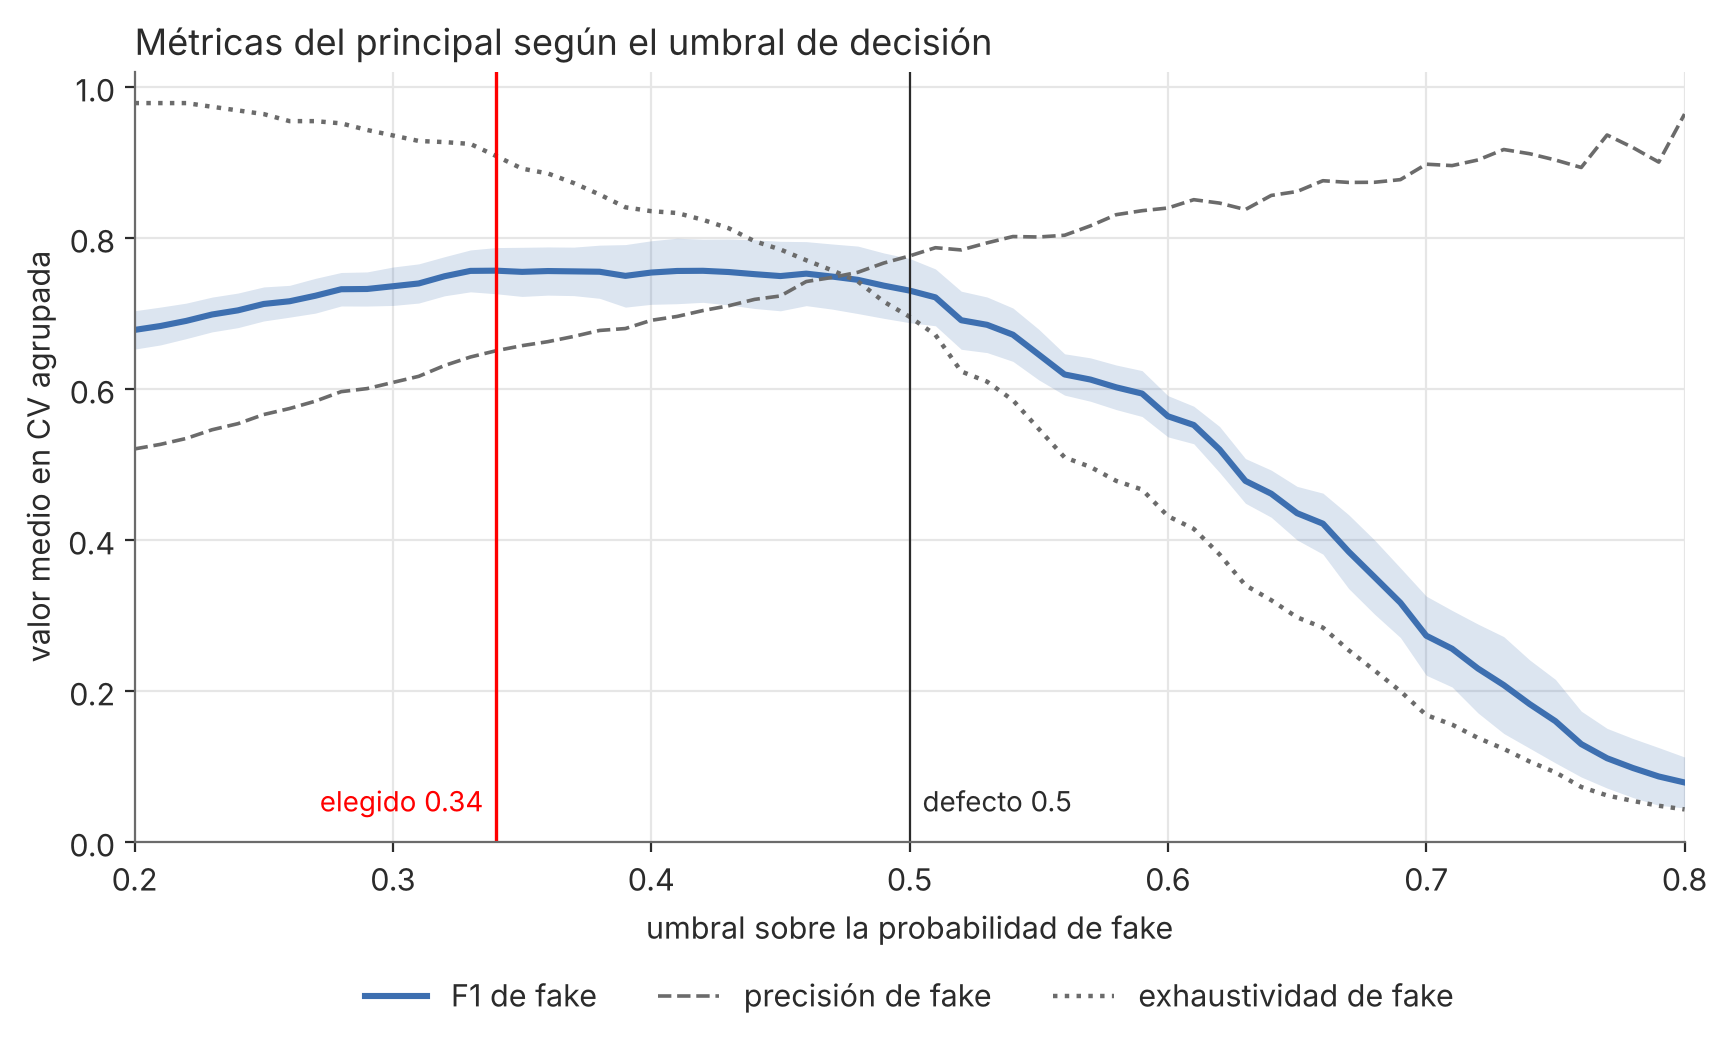

In [9]:
fig, ax = plt.subplots(figsize = (10, 5))
ax.fill_between(curva['umbral'], curva['F1_fake'] - curva['F1_fake_se'], curva['F1_fake'] + curva['F1_fake_se'], color = '#3D6FB0', alpha = 0.18, linewidth = 0)
ax.plot(curva['umbral'], curva['F1_fake'], color = '#3D6FB0', linewidth = 2.2, label = 'F1 de fake')
ax.plot(curva['umbral'], curva['precision_fake'], color = TINTA_SUAVE, linestyle = '--', linewidth = 1.3, label = 'precisión de fake')
ax.plot(curva['umbral'], curva['recall_fake'], color = TINTA_SUAVE, linestyle = ':', linewidth = 1.6, label = 'exhaustividad de fake')
ax.axvline(UMBRAL_DEFECTO, color = TINTA, linewidth = 0.8)
ax.axvline(umbral_elegido, color = 'red', linewidth = 1.2)
ax.text(UMBRAL_DEFECTO + 0.005, 0.04, 'defecto 0.5', color = TINTA, fontsize = 10)
ax.text(umbral_elegido - 0.005, 0.04, f'elegido {umbral_elegido:.2f}', color = 'red', fontsize = 10, ha = 'right')
ax.set_xlim(0.2, 0.8)
ax.set_ylim(0, 1.02)
ax.set_xlabel('umbral sobre la probabilidad de fake')
ax.set_ylabel('valor medio en CV agrupada')
ax.set_title('Métricas del principal según el umbral de decisión')
ax.legend(loc = 'upper center', bbox_to_anchor = (0.5, -0.14), ncol = 3)
guardar(fig, '2_1_umbral_curva_cv')
plt.show()

**Qué se observa.**

* **Umbral elegido: 0.34**, con F1 de fake media de **0.756** contra 0.730 con 0.5 (+0.026). La precisión baja de 0.776 a 0.650 y la exhaustividad sube de 0.695 a 0.908.
* **Meseta.** Entre 0.30 y 0.45 la F1 media queda entre 0.736 y 0.756: la curva es plana en esa zona, así que el valor exacto importa poco. Arriba de 0.5 cae rápido (0.645 con 0.55).
* **Costo.** La exactitud baja de 0.755 a 0.718 y la macro-F1 de 0.752 a 0.709: la F1 de fake sube porque se detectan más falsas, a cambio de marcar más verdaderas como falsas.
* **Incertidumbre.** La ganancia (+0.026) es menor que un error estándar entre folds (0.031 en el umbral elegido). En la CV sola no queda demostrada.

**Bajar el umbral a la zona 0.30–0.45 sube la F1 de fake en CV; el máximo cae en 0.34, pero cualquier punto de la meseta da casi lo mismo.**

<a id="seccion-3"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 3: Estimación honesta con CV anidada</span></div>

> **Qué se hace:** repetimos la elección del umbral **sin ver el fold que se evalúa**: para cada fold, elegimos el umbral con CV interna sobre los otros 4 (agrupada igual) y lo aplicamos al fold que quedó fuera.
>
> **Qué se espera ver:** una ganancia menor que la de la Sección 2, porque ahí el umbral se eligió viendo los 5 folds y eso es optimista.

#### Glosario de la sección
* **CV anidada:** dos niveles de validación. El interno elige (aquí, el umbral); el externo mide qué tan bien funciona esa elección en datos que no participaron en ella.
* **Por qué hace falta:** si elegimos entre 61 umbrales el que mejor sale en los 5 folds, su puntaje lleva "suerte" incluida. El externo la quita.

In [10]:
filas = []
for k in range(5):
    afuera = folds == k
    dentro = corpus[~afuera]
    prob_interna = np.zeros(len(dentro))
    for j in sorted(set(folds[~afuera])):
        en_j = dentro['fold_grupo'].values == j
        prob_interna[en_j] = probabilidad_fake(dentro[~en_j], dentro[en_j])
    y_dentro, folds_dentro = dentro['Category'].values, dentro['fold_grupo'].values
    tabla = pd.DataFrame({'umbral': UMBRALES,
                          'F1_fake': [np.mean([uf.f1_fake(y_dentro[folds_dentro == j], clases(prob_interna[folds_dentro == j], u))
                                               for j in sorted(set(folds_dentro))]) for u in UMBRALES]})
    u_k = elegir_umbral(tabla)
    filas.append({'fold externo': k, 'umbral elegido (interno)': u_k,
                  'F1 fake con 0.5': uf.f1_fake(y[afuera], clases(prob_oof[afuera], UMBRAL_DEFECTO)),
                  'F1 fake con umbral interno': uf.f1_fake(y[afuera], clases(prob_oof[afuera], u_k))})
anidado = pd.DataFrame(filas)
anidado['diferencia'] = anidado['F1 fake con umbral interno'] - anidado['F1 fake con 0.5']
guardar_csv(anidado, 'umbral_anidado')

'resultados/umbral_anidado.csv'

**Tabla 3.1.** Umbral elegido en cada CV interna y F1 de fake en el fold externo.

In [11]:
resumen_anidado = pd.concat([anidado, pd.DataFrame([{'fold externo': 'media', 'umbral elegido (interno)': anidado['umbral elegido (interno)'].mean(),
                                                     'F1 fake con 0.5': anidado['F1 fake con 0.5'].mean(),
                                                     'F1 fake con umbral interno': anidado['F1 fake con umbral interno'].mean(),
                                                     'diferencia': anidado['diferencia'].mean()},
                                                    {'fold externo': 'sd', 'umbral elegido (interno)': anidado['umbral elegido (interno)'].std(),
                                                     'F1 fake con 0.5': anidado['F1 fake con 0.5'].std(),
                                                     'F1 fake con umbral interno': anidado['F1 fake con umbral interno'].std(),
                                                     'diferencia': anidado['diferencia'].std()}])], ignore_index = True)
print(f'Folds en que el umbral interno mejora: {int((anidado["diferencia"] > 0).sum())} de 5')
resumen_anidado.round(4)

Folds en que el umbral interno mejora: 3 de 5


,fold externo,umbral elegido (interno),F1 fake con 0.5,F1 fake con umbral interno,diferencia
0,0,0.3900,0.7848,0.8521,0.0673
1,1,0.3600,0.8541,0.8035,-0.0506
2,2,0.4300,0.6345,0.6832,0.0487
3,3,0.3800,0.6375,0.6528,0.0153
4,4,0.3900,0.7381,0.7292,-0.0089
5,media,0.3900,0.7298,0.7442,0.0144
6,sd,0.0255,0.0951,0.0828,0.0468


**Qué se observa.**

* **El umbral es estable.** Las 5 CV internas eligen entre 0.36 y 0.43 (media 0.39, sd 0.026): todos por debajo de 0.5. El 0.34 de la Sección 2 queda un poco más abajo que cualquiera de ellos, pero dentro de la meseta.
* **La ganancia honesta es pequeña.** En los folds externos la F1 de fake pasa de 0.730 a **0.744** (+0.014 ± 0.047). Mejora en 3 de 5 folds (0: +0.067, 2: +0.049, 3: +0.015) y empeora en 2 (1: −0.051, 4: −0.009).

**La dirección del ajuste es consistente (siempre bajar el umbral), pero en CV la ganancia esperada es de apenas +0.014, con mucha variación entre folds. Antes del test, la expectativa razonable era una mejora pequeña e incierta.**

<a id="fase-evaluacion"></a>

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Metodología CRISP-DM: Evaluación (sistema aparte)</span></div>

<a id="seccion-4"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 4: Aplicación única en el test</span></div>

> **Qué se hace:** entrenamos el principal con las 961 noticias (el mismo modelo que `modelos/modelo_principal.joblib`), calculamos la probabilidad de *fake* del test y aplicamos el umbral elegido en la Sección 2. Se corre **una sola vez**.
>
> **Qué se espera ver:** más exhaustividad y menos precisión que el principal; la F1 de fake puede subir o no, porque el test viene de otra versión del corpus.

Usamos los **mismos 1,000 remuestreos bootstrap** que `evaluacion.ipynb` (misma semilla), así que la diferencia con el principal se mide de forma pareada.

In [12]:
test = pd.read_parquet(os.path.join(uf.RUTA_PROCESADOS, 'test.parquet'))
y_test = test['Category'].values
prob_test = probabilidad_fake(corpus, test)
pred_principal = clases(prob_test, UMBRAL_DEFECTO)
pred_umbral = clases(prob_test, umbral_elegido)

guardadas = pd.read_csv(os.path.join(uf.RUTA_RESULTADOS, 'predicciones_test.csv'))
iguales = (guardadas.set_index('id_unico').loc[test['id_unico'], 'LR texto (principal)'].values == pred_principal).mean()
print(f'Predicciones con 0.5 iguales a las de evaluacion.ipynb: {100 * iguales:.1f} %')

with open(os.path.join('modelos', 'config_umbral.json'), 'w', encoding = 'utf-8') as f:
    json.dump({**config, 'umbral': umbral_elegido}, f, ensure_ascii = False, indent = 1)
guardar_csv(pd.DataFrame({'id_unico': test['id_unico'], 'Category': y_test, 'prob_fake': prob_test.round(4),
                          'LR texto (principal)': pred_principal, f'LR texto, umbral {umbral_elegido:.2f}': pred_umbral}), 'predicciones_test_umbral')

Predicciones con 0.5 iguales a las de evaluacion.ipynb: 100.0 %


'resultados/predicciones_test_umbral.csv'

**Tabla 4.1.** Métricas en el test. El intervalo es bootstrap del 95 %.

In [13]:
rng = np.random.default_rng(SEMILLA)
indices_boot = rng.integers(0, len(test), size = (N_BOOTSTRAP, len(test)))
boot_principal = np.array([uf.f1_fake(y_test[i], pred_principal[i]) for i in indices_boot])
boot_umbral = np.array([uf.f1_fake(y_test[i], pred_umbral[i]) for i in indices_boot])

nombre_umbral = f'LR texto, umbral {umbral_elegido:.2f} (sistema aparte)'
filas = []
for nombre, pred, boot, cv in [('LR texto (principal, umbral 0.5)', pred_principal, boot_principal, anidado['F1 fake con 0.5'].mean()),
                               (nombre_umbral, pred_umbral, boot_umbral, anidado['F1 fake con umbral interno'].mean())]:
    m = uf.metricas(y_test, pred)
    filas.append({'sistema': nombre, **{c: round(v, 4) for c, v in m.items()},
                  'IC95 F1_fake': f'[{np.percentile(boot, 2.5):.3f}, {np.percentile(boot, 97.5):.3f}]',
                  'F1_fake en CV (anidada)': round(cv, 3), 'predichas Fake': int((pred == 'Fake').sum())})
resultados_umbral = pd.DataFrame(filas).set_index('sistema')
guardar_csv(resultados_umbral, 'umbral_test', index = True)
resultados_umbral

,F1_fake,F1_true,F1_macro,accuracy,precision_fake,recall_fake,IC95 F1_fake,F1_fake en CV (anidada),predichas Fake
sistema,,,,,,,,,
"LR texto (principal, umbral 0.5)",0.6764,0.7669,0.7217,0.7290,0.8394,0.5664,"[0.629, 0.722]",0.730,193
"LR texto, umbral 0.34 (sistema aparte)",0.7346,0.6882,0.7114,0.7133,0.6837,0.7937,"[0.696, 0.771]",0.744,332


**Tabla 4.2.** Umbral elegido frente al principal: bootstrap pareado y McNemar exacta; y frente al baseline oficial.

In [14]:
dif_boot = boot_umbral - boot_principal
ok_u, ok_p = pred_umbral == y_test, pred_principal == y_test
b, c = int((ok_u & ~ok_p).sum()), int((~ok_u & ok_p).sum())
p_mcnemar = stats.binomtest(b, b + c, 0.5).pvalue
pd.DataFrame([
    ('Umbral − principal: diferencia de F1 de fake (bootstrap pareado)', f'{uf.f1_fake(y_test, pred_umbral) - uf.f1_fake(y_test, pred_principal):+.3f}',
     f'IC95 [{np.percentile(dif_boot, 2.5):+.3f}, {np.percentile(dif_boot, 97.5):+.3f}]'),
    ('Remuestreos en que el umbral gana', f'{int((dif_boot > 0).sum())} de {N_BOOTSTRAP}', '—'),
    ('McNemar exacta (aciertos)', f'solo umbral: {b}; solo principal: {c}', f'p = {p_mcnemar:.3g}'),
    ('Remuestreos en que el umbral supera el baseline oficial (.7217)', f'{int((boot_umbral > BASELINE_OFICIAL).sum())} de {N_BOOTSTRAP}', '—'),
], columns = ['comparación', 'datos', 'resultado'])

,comparación,datos,resultado
0,Umbral − principal: diferencia de F1 de fake (...,+0.058,"IC95 [+0.012, +0.103]"
1,Remuestreos en que el umbral gana,993 de 1000,—
2,McNemar exacta (aciertos),solo umbral: 65; solo principal: 74,p = 0.498
3,Remuestreos en que el umbral supera el baselin...,744 de 1000,—


**Tabla 4.3.** Sensibilidad: F1 de fake en el test con otros umbrales. **No se usa para elegir nada**; solo responde si el resultado depende de haber caído justo en 0.34. Incluye los umbrales que eligió cada CV interna de la Sección 3.

In [15]:
umbrales_revisar = sorted(set([0.30, umbral_elegido, 0.45, UMBRAL_DEFECTO] + list(anidado['umbral elegido (interno)'])))
filas = []
for u in umbrales_revisar:
    pred = clases(prob_test, u)
    m = uf.metricas(y_test, pred)
    origen = 'elegido (CV completa)' if u == umbral_elegido else ('defecto' if u == UMBRAL_DEFECTO else
             ('CV interna, fold ' + ', '.join(str(k) for k in anidado.loc[anidado['umbral elegido (interno)'] == u, 'fold externo']) if u in set(anidado['umbral elegido (interno)']) else 'referencia'))
    filas.append({'umbral': u, 'origen': origen, 'F1_fake': m['F1_fake'], 'precision_fake': m['precision_fake'],
                  'recall_fake': m['recall_fake'], 'F1_macro': m['F1_macro'], 'accuracy': m['accuracy']})
pd.DataFrame(filas).round(3)

,umbral,origen,F1_fake,precision_fake,recall_fake,F1_macro,accuracy
0,0.30,referencia,0.720,0.635,0.832,0.669,0.677
1,0.34,elegido (CV completa),0.735,0.684,0.794,0.711,0.713
2,0.36,"CV interna, fold 1",0.729,0.695,0.766,0.714,0.715
3,0.38,"CV interna, fold 3",0.737,0.720,0.755,0.731,0.731
4,0.39,"CV interna, fold 0, 4",0.738,0.728,0.748,0.734,0.734
5,0.43,"CV interna, fold 2",0.707,0.759,0.661,0.724,0.726
6,0.45,referencia,0.705,0.785,0.640,0.730,0.733
7,0.50,defecto,0.676,0.839,0.566,0.722,0.729


**Figura 4.1.** Matrices de confusión en el test: principal (0.5) y umbral elegido.

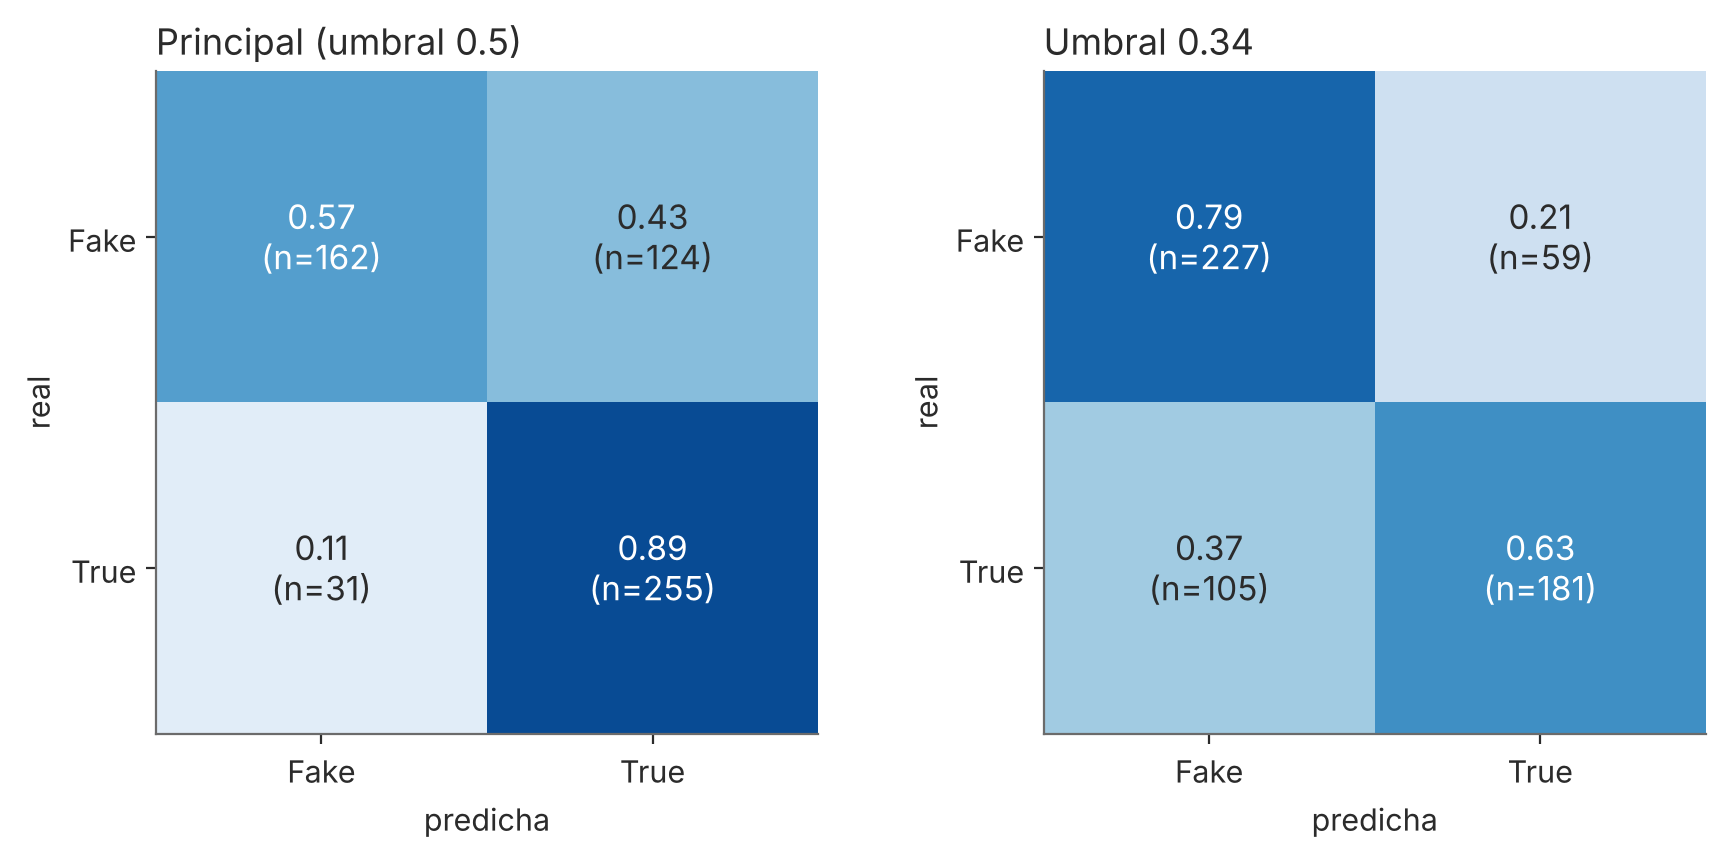

In [16]:
etiquetas = ['Fake', 'True']
fig, ejes = plt.subplots(1, 2, figsize = (10.5, 4.3))
for ax, (titulo, pred) in zip(ejes, [('Principal (umbral 0.5)', pred_principal), (f'Umbral {umbral_elegido:.2f}', pred_umbral)]):
    cm = confusion_matrix(y_test, pred, labels = etiquetas)
    cm_norm = cm / cm.sum(axis = 1, keepdims = True)
    ax.imshow(cm_norm, cmap = 'Blues', vmin = 0, vmax = 1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{cm_norm[i, j]:.2f}\n(n={cm[i, j]})', ha = 'center', va = 'center', color = 'white' if cm_norm[i, j] > 0.5 else TINTA, fontsize = 12)
    ax.set_xticks([0, 1], etiquetas)
    ax.set_yticks([0, 1], etiquetas)
    ax.set_xlabel('predicha')
    ax.set_ylabel('real')
    ax.set_title(titulo)
    ax.grid(False)
guardar(fig, '4_1_umbral_matrices_confusion')
plt.show()

**Qué se observa.**

* **Verificación.** Con 0.5, el modelo reentrenado da exactamente las mismas 572 predicciones que `evaluacion.ipynb`.
* **Resultado** (Tabla 4.1). Con el umbral 0.34, la F1 de fake en el test sube de 0.676 a **0.735** (IC95 [0.696, 0.771]). La exhaustividad pasa de 0.566 a 0.794 y la precisión de 0.839 a 0.684; ahora se predicen 332 falsas (hay 286).
* **Frente al principal** (Tabla 4.2). La diferencia es de +0.058 con IC95 pareado [+0.012, +0.103]; el umbral gana en 993 de 1,000 remuestreos. **En F1 de fake la mejora sí es clara.**
* **Pero no acierta más noticias.** La exactitud baja de 0.729 a 0.713 y la macro-F1 de 0.722 a 0.711. McNemar no distingue los dos sistemas (65 noticias acierta solo el umbral y 74 solo el principal; p = 0.498). En la matriz de confusión (Figura 4.1), se detectan 65 falsas más (162 → 227) a cambio de marcar 74 verdaderas más como falsas (31 → 105).
* **Frente al baseline oficial.** 0.735 queda por encima del BoW + SVM oficial (.7217) y del BETO oficial (.7321), pero .7217 está dentro del intervalo: el umbral lo supera en 744 de 1,000 remuestreos. No es una diferencia demostrada.
* **Sensibilidad** (Tabla 4.3). Los umbrales que eligieron las CV internas (0.36 a 0.43) dan entre 0.707 y 0.738 en el test, y toda la zona 0.30–0.45 queda arriba del principal. El resultado no depende de haber caído justo en 0.34.

**El umbral no hace al modelo más acertado: cambia qué error comete. Con la métrica oficial (F1 de fake) ese cambio conviene, y la estimación puntual pasa del baseline oficial, aunque sin significancia.**

<a id="seccion-5"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 5: Qué noticias cambian</span></div>

> **Qué se hace:** vemos dónde caen las probabilidades del test frente a las de CV y qué grupos de falsas recupera el umbral (longitud y tipo de fuente, los dos factores de la Sección 6 de `evaluacion.ipynb`).
>
> **Qué se espera ver:** que el umbral recupere sobre todo falsas largas, que eran las que más se escapaban.

**Tabla 5.1.** Probabilidad de *fake* en CV (fuera de fold) y en el test, por clase real.

In [17]:
filas = []
for nombre, p, yy in [('CV (fuera de fold)', prob_oof, y), ('test', prob_test, y_test)]:
    for clase in ['Fake', 'True']:
        filas.append({'conjunto': nombre, 'clase real': clase, 'mediana': np.median(p[yy == clase]),
                      f'% ≥ {UMBRAL_DEFECTO}': 100 * np.mean(p[yy == clase] >= UMBRAL_DEFECTO),
                      f'% ≥ {umbral_elegido:.2f}': 100 * np.mean(p[yy == clase] >= umbral_elegido)})
pd.DataFrame(filas).round(3)

,conjunto,clase real,mediana,% ≥ 0.5,% ≥ 0.34
0,CV (fuera de fold),Fake,0.567,69.831,91.350
1,CV (fuera de fold),True,0.324,18.480,46.201
2,test,Fake,0.545,56.643,79.371
3,test,True,0.294,10.839,36.713


**Tabla 5.2.** Falsas detectadas y verdaderas acertadas en el test, por cuartil de longitud y por tipo de fuente.

In [18]:
analisis = test.assign(ok_principal = ok_p, ok_umbral = ok_u)
analisis['cuartil de longitud'] = pd.qcut(analisis['est_log_palabras'], 4, labels = ['Q1 (más cortas)', 'Q2', 'Q3', 'Q4 (más largas)'])

def por_grupo(columna):
    '''
    Función que compara aciertos del principal y del umbral elegido por grupo

    inputs:
    --------
        columna (str): Columna de agrupación del test

    outputs:
    --------
        pandas.DataFrame: Falsas detectadas y verdaderas acertadas (%) con cada umbral
    '''
    filas = []
    for valor, d in analisis.groupby(columna, observed = True):
        falsas, verdaderas = d[d['y'] == 1], d[d['y'] == 0]
        filas.append({columna: valor, 'falsas': len(falsas),
                      'falsas detectadas 0.5 (%)': 100 * falsas['ok_principal'].mean(),
                      f'falsas detectadas {umbral_elegido:.2f} (%)': 100 * falsas['ok_umbral'].mean(),
                      'verdaderas': len(verdaderas),
                      'verdaderas acertadas 0.5 (%)': 100 * verdaderas['ok_principal'].mean(),
                      f'verdaderas acertadas {umbral_elegido:.2f} (%)': 100 * verdaderas['ok_umbral'].mean()})
    return pd.DataFrame(filas).set_index(columna).round(1)

pd.concat({c: por_grupo(c) for c in ['cuartil de longitud', 'fuente_verificador']}, names = ['grupo', 'valor'])

falsas  falsas detectadas 0.5 (%)  \
grupo               valor                                                
cuartil de longitud Q1 (más cortas)     110                       78.2   
                    Q2                   81                       54.3   
                    Q3                   62                       38.7   
                    Q4 (más largas)      33                       24.2   
fuente_verificador  False               169                       48.5   
                    True                117                       68.4   

                                     falsas detectadas 0.34 (%)  verdaderas  \
grupo               valor                                                     
cuartil de longitud Q1 (más cortas)                        90.9          33   
                    Q2                                     75.3          63   
                    Q3                                     72.6          80   
                    Q4 (más largas)                        63.6         110   
fuente_verificador  False                                  74.0         285   
                    True                                   87.2           1   

                                     verdaderas acertadas 0.5 (%)  \
grupo               valor                                           
cuartil de longitud Q1 (más cortas)                          69.7   
                    Q2                                       82.5   
                    Q3                                       90.0   
                    Q4 (más largas)                          98.2   
fuente_verificador  False                                    89.1   
                    True                                    100.0   

                                     verdaderas acertadas 0.34 (%)  
grupo               valor                                           
cuartil de longitud Q1 (más cortas)                           39.4  
                    Q2                                        50.8  
                    Q3                                        60.0  
                    Q4 (más largas)                           80.0  
fuente_verificador  False                                     63.5  
                    True                                       0.0

**Qué se observa.**

* **El test está corrido hacia *True*** (Tabla 5.1). Las falsas del test tienen menos probabilidad de *fake* que las de CV: solo el 56.6 % pasa de 0.5, contra el 69.8 % en CV. Lo mismo con las verdaderas (10.8 % contra 18.5 %). Es el cambio de dominio de la versión 1.0 a la 2.0 que ya se veía con las cifras (`notas/resumen_reunion.md`). Bajar el umbral compensa parte de ese corrimiento; por eso la ganancia en el test (+0.058) es mayor que la de la CV anidada (+0.014).
* **Se recuperan sobre todo las falsas largas** (Tabla 5.2). En el cuartil más largo se detecta el 63.6 % (antes 24.2 %); en Q3, el 72.6 % (antes 38.7 %). Las falsas de fuentes no verificadoras pasan de 48.5 % a 74.0 %.
* **Lo pagan las verdaderas cortas.** En Q1 se acierta solo el 39.4 % de las verdaderas (antes 69.7 %); en Q2, el 50.8 % (antes 82.5 %).

**El sesgo de longitud no desaparece: el modelo sigue ordenando las noticias por qué tan "de prensa" se ven, y el umbral solo mueve la línea de corte. Ahora se equivoca menos con las falsas largas y más con las verdaderas cortas.**

<a id="conclusiones"></a>

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Conclusiones</span></div>

<a id="seccion-6"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 6: Resumen y limitaciones</span></div>

> **Qué se hace:** reunimos los resultados y lo que queda abierto.
>
> **Qué se espera ver:** una respuesta directa: ¿vale la pena el umbral?

**Tabla 6.1.** Resumen (F1 de fake).

| Sistema | CV agrupada | CV anidada | Test | IC95 test |
|:--|--:|--:|--:|:--|
| LR texto (principal, umbral 0.5) | 0.730 | 0.730 | 0.676 | [0.629, 0.722] |
| **LR texto, umbral 0.34 (sistema aparte)** | 0.756 | 0.744 | **0.735** | [0.696, 0.771] |
| *Oficial: baseline BoW + SVM* | — | — | *0.7217* | — |
| *Oficial: baseline BETO* | — | — | *0.7321* | — |

La columna *CV agrupada* del umbral es optimista (se eligió viendo los 5 folds); la honesta es la *CV anidada*.

**¿Vale la pena el umbral?** Para la métrica oficial, sí: +0.058 en el test con IC95 pareado que no incluye el 0, y estable en toda la zona 0.30–0.45. Para el negocio depende de qué cuesta más: el principal es un filtro de alta precisión (84 % de lo que marca es falso), el umbral es un detector más exhaustivo (atrapa el 79 % de las falsas, pero 32 % de lo que marca es verdadero).

**Limitaciones:**

* **Sistema aparte.** El umbral se eligió solo con CV, pero la decisión de probarlo vino de ver la baja exhaustividad en el test. No reemplaza al principal en el reporte; se presenta junto a él.
* **La CV anidada esperaba poco** (+0.014 ± 0.047). Parte de la ganancia en el test se debe a que el test está corrido hacia *True*; si el corrimiento hubiera ido al revés, el umbral habría perjudicado.
* **El test está balanceado (50 % falsas).** Con menos falsas en la vida real, bajar el umbral generaría proporcionalmente más falsas alarmas; la precisión de 0.684 no se sostendría.
* **Exactitud y macro-F1 bajan** (0.729 → 0.713 y 0.722 → 0.711). Si el reporte usa la macro-F1 como complementaria, hay que decirlo.
* **Las probabilidades no están calibradas.** El umbral se eligió con modelos entrenados con 4 de 5 folds y se aplica al modelo entrenado con todo.

**Decisiones para el equipo:**

1. Reportar el umbral 0.34 como sistema aparte junto al principal (propuesta), o solo como análisis de sensibilidad.
2. Qué umbral usa la API de demostración: `modelos/config_umbral.json` guarda el 0.34; también se puede mostrar la probabilidad y dejar que el usuario vea ambos cortes.